In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC_patient_split,
    find_all_indices,
    get_freqs,
    hot_coding,
)
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient, color_palette_full, custom_cmap

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
class_task = "cancer_vs_hbd"
class_task = "MC"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)


MC

Healthy: 89 entries
Cancer: 91 entries
Mild dysplasia: 0 entries
Severe dysplasia: 24 entries
Benign: 22 entries
Available cases: ['Benign' 'Cancer' 'Healthy' 'Severe dysplasia']
Coding: -> forward
{np.str_('Benign'): [1, 0, 0, 0], np.str_('Cancer'): [0, 1, 0, 0], np.str_('Healthy'): [0, 0, 1, 0], np.str_('Severe dysplasia'): [0, 0, 0, 1]}

Inverse mapping: {(1, 0, 0, 0): 'Benign', (0, 1, 0, 0): 'Cancer', (0, 0, 1, 0): 'Healthy', (0, 0, 0, 1): 'Severe dysplasia'}


In [6]:
print(X.shape, Y.shape, labels.shape)

(226, 31, 7728) (226, 4) (226,)


Train patients: [44 63  3 72 46 49  6 99 83 77 61 81 90 69 52 28 18 57 64 75  1 62 43 42
  4 15 17 41 39  5 91 60  0 35 29 51 11 36 23 53 10 32 67 58 80 86 33 85
 14 89 19 30 50 97 98 70 20 94 73 78 25 38 82 47 40 66 59 12 71 88 37 21
 84  9 96 68 65 48 45]
Test patients: [27 87  2 56 76 93 16 74 55 95 54 92 79 13  7 31 22 24 34  8]
NaN values are replaced by 0.
Training: 180 samples from 79 patients
Testing:  46 samples from 20 patients
Data shapes: (180, 239568), (46, 239568), (180, 4), (46, 4)


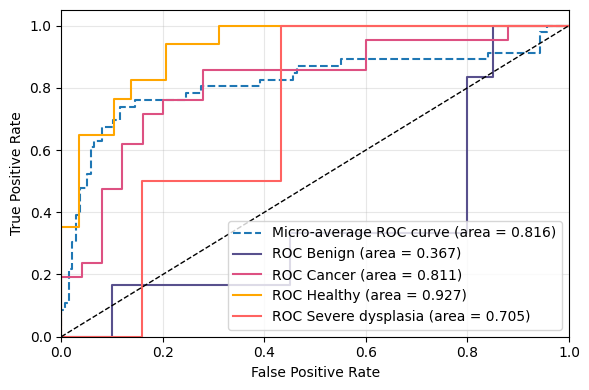

Average ROC AUC = 0.7024
Patient-based split: 79 training patients, 20 testing patients


(np.float64(0.7024045950668669),
 {'roc_auc_Benign': 0.3666666666666666,
  'roc_auc_Cancer': 0.8114285714285714,
  'roc_auc_Healthy': 0.9269776876267749,
  'roc_auc_Severe dysplasia': 0.7045454545454545})

In [7]:
compute_ROC_patient_split(
    X[:, :, :],
    Y,
    patient_ids=Case,
    test_size=0.2,
    plot=True,
    random_state=0,
    inverse_mapping=inverse_mapping,
)

## Frequency sweep with ranked frequencies from PCA

**1. All IIVV patterns (baseline)**

In [8]:
random_state = 0

Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 0  1  3  4  5  6  8  9 10 11 12 14 15 17 18 19 20 21 23 25 28 29 30 32
 33 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 57 58 59 60
 61 62 63 64 65 66 67 68 69 70 71 72 73 75 77 78 80 81 82 83 84 85 86 88
 89 90 91 94 96 97 98 99]
Test patients: [27 87  2 56 76 93 16 74 55 95 54 92 79 13  7 31 22 24 34]
Fold 1: 80.5% train / 19.5% test
Fold 1: 80.5% train / 19.5% test
  Training: 182 samples from 80 patients
  Testing:  44 samples from 19 patients
Fold 1 frequency ranking (top 10): [ 7  0 30 12  8 13 23 16 27 29]
Train patients: [ 0  1  2  4  5  7  9 10 11 12 13 14 15 16 17 19 20 21 22 23 24 25 27 29
 30 31 32 33 34 35 36 37 38 39 40 41 42 43 45 47 48 50 51 53 54 55 56 58
 59 60 62 64 65 66 67 68 70 71 73 74 75 76 78 79 80 82 84 85 86 87 88 89
 91 92 93 94 95 96 97 98]
Test patients: [ 8 44 63  3 72 46 49  6 99 83 77 61 81 90 69 52 28 18 57]
Fold 2: 77.0% train / 23.0% 

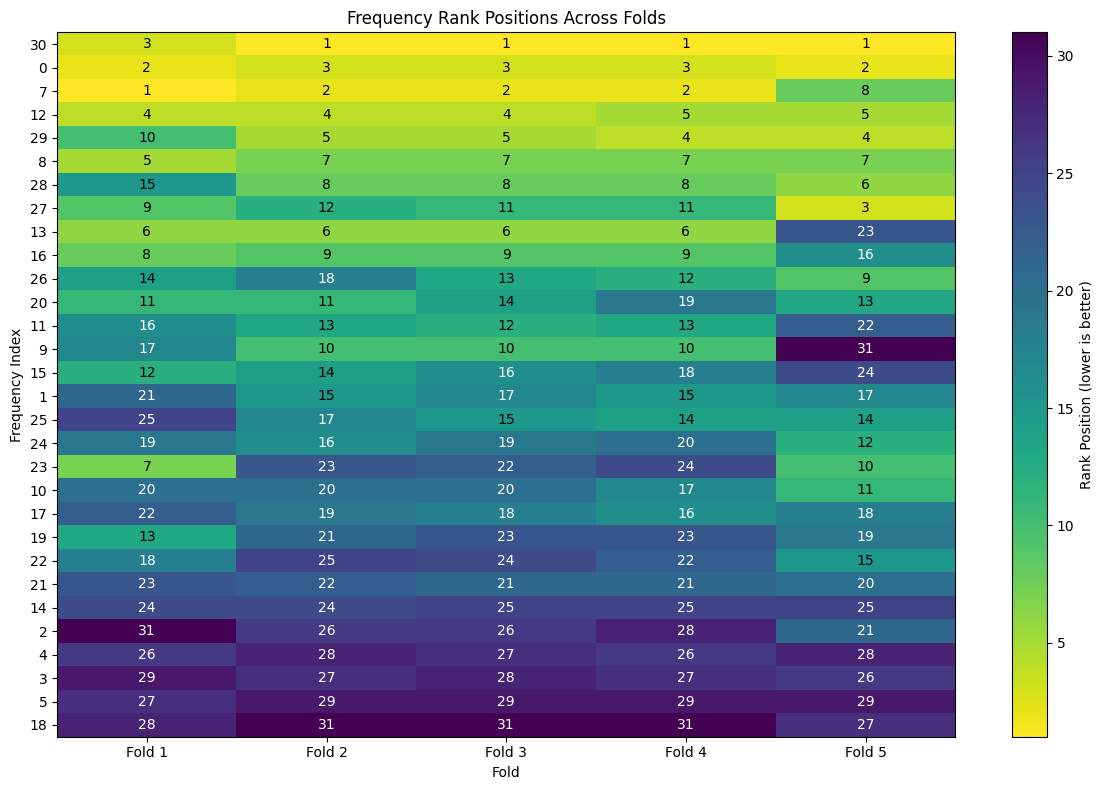

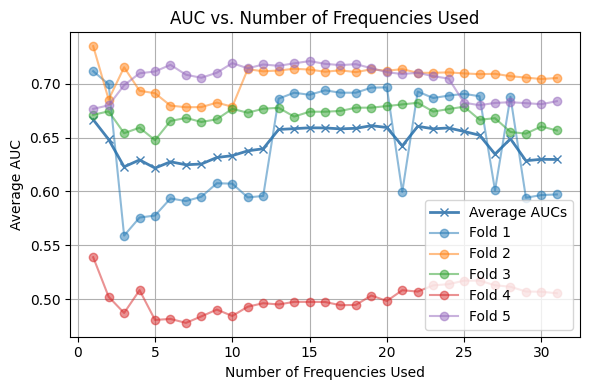

In [9]:
aucs_baseline, top_freqs_baseline, fold_rankings_baseline, fold_aucs_baseline = (
    combined_frequency_roc_analysis(
        X,
        Y,
        Case,
        max_freqs=31,
        n_folds=5,
        random_state=random_state,
        # s_name="results/baseline",
    )
)

## Save/overview of results

In [10]:
np.savez(
    f"results/freq_fold_results_{class_task}.npz",
    fold_rankings_baseline=fold_rankings_baseline,
    aucs_baseline=aucs_baseline,
    top_freqs_baseline=top_freqs_baseline,
    fold_aucs_baseline=fold_aucs_baseline,
    # LongAcross=fold_rankings_la,
    # LongAcrossExt=fold_rankings_lae,
    # Skip1=fold_rankings_s1,
)

In [11]:
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
fold_rankings_baseline = tmp["fold_rankings_baseline"]
aucs_baseline = tmp["aucs_baseline"]
top_freqs_baseline = tmp["top_freqs_baseline"]
fold_aucs_baseline = tmp["fold_aucs_baseline"].tolist()

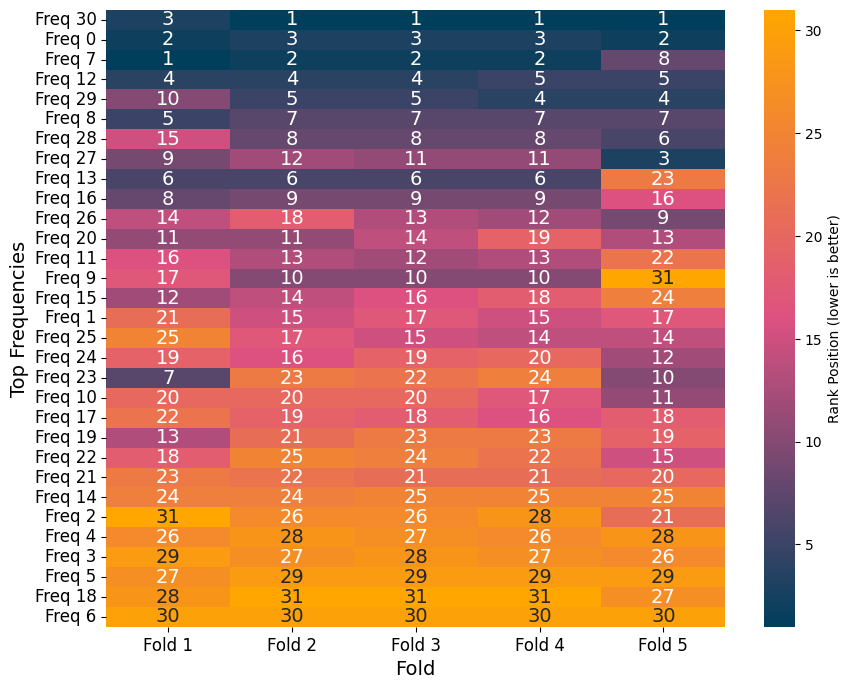

In [12]:
def plot_fold_rankings(fold_rankings_dict, top_n_freqs=20, class_task="unnamed"):
    """
    Visualizes fold frequency rankings as heatmaps for multiple ranking sets.

    Parameters:
        fold_rankings_dict : dict
            Dictionary where keys are method names and values are lists of np.arrays (fold rankings).
        top_n_freqs : int
            Number of top composite frequencies to display in the heatmap.
    """
    for name, rankings in fold_rankings_dict.items():
        n_folds = len(rankings)
        n_freqs = len(rankings[0])

        # Composite ranking across folds for sorting
        score_accumulator = np.zeros(n_freqs)
        for fold in rankings:
            for rank, freq_idx in enumerate(fold):
                score_accumulator[freq_idx] += n_freqs - rank

        composite_ranking = np.argsort(score_accumulator)[::-1][:top_n_freqs]

        # Create rank matrix: rows = top freqs, cols = folds
        rank_matrix = np.full((top_n_freqs, n_folds), np.nan)
        for f_idx, fold in enumerate(rankings):
            for i, freq in enumerate(composite_ranking):
                pos = np.where(fold == freq)[0]
                if pos.size > 0:
                    rank_matrix[i, f_idx] = pos[0] + 1  # +1 for 1-based rank

        plt.figure(figsize=(9, 7))
        sns.heatmap(
            rank_matrix,
            annot=True,
            fmt=".0f",
            cmap=cmap_gradient,
            cbar_kws={"label": "Rank Position (lower is better)"},
            xticklabels=[f"Fold {i+1}" for i in range(n_folds)],
            yticklabels=[f"Freq {f}" for f in composite_ranking],
            annot_kws={"fontsize": 14},
        )
        plt.xlabel("Fold", fontsize=14)
        plt.ylabel("Top Frequencies", fontsize=14)

        plt.xticks(fontsize=12)  # rotate if needed
        plt.yticks(fontsize=12)
        plt.tight_layout()
        plt.savefig(
            f"results/Fold-wise_frequency_impact_rankings_{name}_{class_task}.pdf",
            bbox_inches="tight",
        )
        plt.show()


fold_rankings_dict = {
    "Baseline": fold_rankings_baseline,
    # "Long-across": fold_rankings_la,
    # "Long-across extend": fold_rankings_lae,
    # "Skip 1": fold_rankings_s1,
}

plot_fold_rankings(fold_rankings_dict, top_n_freqs=31, class_task=class_task)

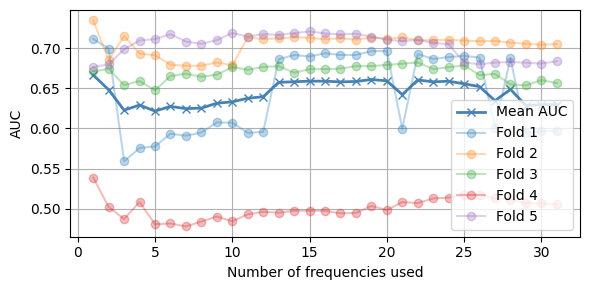

In [13]:
# Plot AUC vs number of frequencies
plt.figure(figsize=(6, 3))
plt.plot(
    range(1, 31 + 1),
    np.nanmean([np.array(v) for v in fold_aucs_baseline.values()], axis=0),
    marker="x",
    color="steelblue",
    linewidth=2,
    label="Mean AUC",
)

# Add individual fold lines
for fold_idx in range(5):
    plt.plot(
        range(1, 31 + 1),
        fold_aucs_baseline[fold_idx],
        "o-",
        alpha=0.3,
        label=f"Fold {fold_idx+1}",
    )

plt.xlabel("Number of frequencies used")
plt.ylabel("AUC")
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"results/baselineaucs_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Frequency input experiment

Since frequency 0 and 30 are the most consistent ones, I'd be curious to see how classification does with just those two frequencies.
So we take the average of the rankings for each frequency and do a classification run through with the top 2, top 5, and then top 12 frequencies.
So in total, 4 different frequency inputs: top 2, top 5, top 12, and all 31 for control (baseline)

In [14]:
freq_idx, freq_list = get_freqs(plot=False)

In [15]:
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

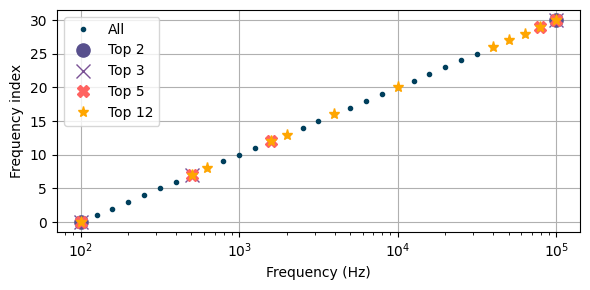

In [16]:
plt.figure(figsize=(6, 3))
plt.plot(freq_list[freq_idx], freq_idx, ".", c="#003F5C", ms=6, label="All")
plt.plot(freq_list[top_2], top_2, "o", c="#58508D", ms=9.5, label="Top 2")
plt.plot(freq_list[top_3], top_3, "x", c="#7A5195", ms=9.5, label="Top 3")
plt.plot(freq_list[top_5], top_5, "X", c="#FF6361", ms=8, label="Top 5")
plt.plot(freq_list[top_12], top_12, "*", c="#FFA600", ms=8, label="Top 12")
plt.legend()
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.xscale("log")
plt.ylabel("Frequency index")
plt.tight_layout()
plt.savefig(f"results/freq_topX_{class_task}.pdf", bbox_inches="tight")
plt.show()

___

### Test top2, top3, top5, top12, all (Baseline)

In [17]:
Freq_sel = {
    "Top 2": top_2,
    "Top 3": top_3,
    "Top 5": top_5,
    "Top 12": top_12,
    "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

In [18]:
results = []
numXparams = []
for Fsel, idxs in Freq_sel.items():
    numXparams.append({"Fsel": Fsel, "n_params": len(X[0, idxs, :].flatten())})
    for trial in range(7):
        print("Trial:", trial, "\n\t", Fsel, idxs)

        avg_roc_auc, _ = compute_ROC_patient_split(
            X[:, idxs, :],
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Fsel": Fsel, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})


df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/freq-analysis_{class_task}.csv", index=False)
df_params.to_csv(f"results/freq-analysis_{class_task}_params.csv", index=False)

Trial: 0 
	 Top 2 [30  0]
Train patients: [44 63  3 72 46 49  6 99 83 77 61 81 90 69 52 28 18 57 64 75  1 62 43 42
  4 15 17 41 39  5 91 60  0 35 29 51 11 36 23 53 10 32 67 58 80 86 33 85
 14 89 19 30 50 97 98 70 20 94 73 78 25 38 82 47 40 66 59 12 71 88 37 21
 84  9 96 68 65 48 45]
Test patients: [27 87  2 56 76 93 16 74 55 95 54 92 79 13  7 31 22 24 34  8]
Trial: 1 
	 Top 2 [30  0]
Train patients: [ 2 45 60 56 19 39 94 28 41 99 37 53 75 71 40 47 67 23 35 86 97 68 15 83
 42 91 27 98 44 54 24  4 57 50 21 87  3 74 31 66 70 43 48 52 95  8 61  0
 90 58 22 62 64  7 96 13 69 85 14 30 29 11 18 20 51 25  6 72 77  1 16 65
 80  5 76  9 73 12 38]
Test patients: [93 84 33 81 79 17 36 82 89 92 46 34 55 78 63 32 59 49 88 10]
Trial: 2 
	 Top 2 [30  0]
Train patients: [36 11 84 45 97  5 25 77 74 63 66  1 18 49 37 78  6 75 91 10 12 54 87 55
 95 33 19 27 61 56  9 96 17 60 58 42 65 46 72  8 71 82 90 98 88 80 51 53
 67 85 47 69 70 81 59 34 39 52 43  4 68 40 38 20 32 64 48 86 93 50 35  7
 76 83 44 22 73 1

In [19]:
df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

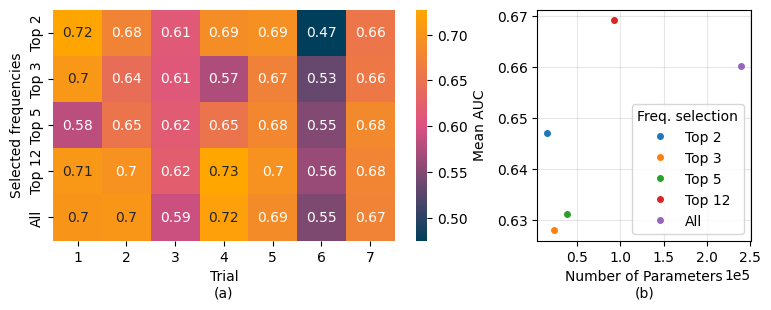

In [22]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel("Selected frequencies")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
    )
ax1.set_xlabel("Number of Parameters\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [23]:
df_plot

,Fsel,n_params,avg. ROC AUC
0,Top 2,15456,0.646949
1,Top 3,23184,0.628001
2,Top 5,38640,0.631165
3,Top 12,92736,0.669221
4,All,239568,0.660275


___